# Compare surrogates and transfer to unseen ores

**Question:** How much does predictive performance change when an entire ore group is absent from training?

Level: 3. Prerequisites: Levels 1 and 2 in this topic. Reading time: 28 minutes.

## Objectives

Compare model families on identical targets and interpolation rows, inspect whole-case transfer and Gaussian-process coverage, and assess what the evidence says about generalization limits.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

For the level 3 03-learning lesson, record the pinned versions before analysis so the environment behind its tables and figures can be reconstructed.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; `data/derived/learning.json` contains versioned results from 3,072 simulated states across twelve authored circuits, MIT project licence. The target labels are engine outputs, not observed plant data. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

The production portfolio includes Ridge, random forest, histogram gradient boosting, Gaussian process and PyTorch MLP. It records RMSE, MAE and $R^2$ under interpolation, leave-one-case-out and leave-one-ore-group-out protocols. The GP's nominal 95% intervals are checked by empirical coverage. Permutation importance indicates reliance within the test domain, not causation.

## Comparison

Random forests (Breiman, 2001), gradient boosting (Friedman, 2001), Gaussian processes (Rasmussen & Williams, 2006) and Adam-trained neural networks (Kingma & Ba, 2015) are established. OreFlow compares them on a common engine-generated design and audits case/ore-group transfer, per-case scores, interval coverage and out-of-envelope detection. It claims no new algorithm or plant-validated improvement; twelve authored cases bound what the record can support.

Read the committed production evaluation and its declared cases, model identities and split sizes.

In [2]:
# Read the committed production evaluation and its declared cases, model identities and split sizes.
record = json.loads((repo / "data/derived/learning.json").read_text(encoding="utf-8"))
print("engine version:", record["engine_version"])
print("design:", record["design"])
print("models:", record["models"])
print(
    "interpolation rows:",
    record["interpolation"]["train_rows"],
    "train /",
    record["interpolation"]["test_rows"],
    "test",
)
print(
    "case folds:",
    len(record["leave_one_case_out"]),
    "| group folds:",
    len(record["leave_one_group_out"]),
)


engine version: 0.10.007
design: {'per_case': 256, 'cases': ['copper_porphyry_soft', 'copper_porphyry_hard', 'gold_free_milling', 'iron_magnetite_fine', 'nickel_sulphide', 'phosphate_clay', 'copper_molybdenum', 'copper_oxide', 'zinc_sulfide', 'mixed_ore_high_clay', 'low_grade_copper', 'refractory_gold'], 'rows': 3072, 'seed': 20260927, 'seconds': 555.6779085000016, 'method': "scrambled Sobol over each case's Contract 1 envelope and ore factors"}
models: ['ridge', 'random_forest', 'hist_gradient_boosting', 'gaussian_process', 'mlp']
interpolation rows: 2460 train / 612 test
case folds: 12 | group folds: 2


Compare recovery errors on the same interpolation rows. Pooled and within-case R² answer different questions.

In [3]:
# Compare recovery errors on the same interpolation rows.
target = "recovery_pct"
rows = []
for name, values in record["interpolation"]["models"].items():
    metric = values[target]
    rows.append(
        {
            "model": name,
            "RMSE (%)": metric["rmse"],
            "MAE (%)": metric["mae"],
            "pooled R²": metric["r2"],
            "within-case R²": metric["r2_within_case"],
        }
    )
score = pd.DataFrame(rows).set_index("model").sort_values("RMSE (%)")
display(score.round(3))


,RMSE (%),MAE (%),pooled R²,within-case R²
model,,,,
mlp,3.382,1.675,0.951,0.936
hist_gradient_boosting,4.603,3.178,0.909,0.881
gaussian_process,5.344,3.600,0.878,0.840
random_forest,6.492,4.538,0.820,0.764
ridge,9.460,6.825,0.617,0.498


Plot RMSE by target, retaining target units. Compare models within each column; do not rank recovery, log-upgrade and energy on one raw scale.

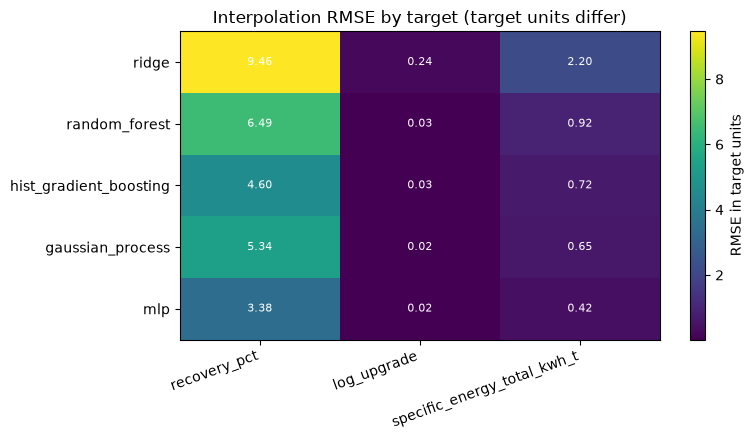

In [4]:
# Plot RMSE by target, retaining target units.
model_names, targets = record["models"], record["targets"]
rmse = np.array(
    [[record["interpolation"]["models"][m][t]["rmse"] for t in targets] for m in model_names]
)
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(rmse, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(targets)), targets, rotation=20, ha="right")
ax.set_yticks(range(len(model_names)), model_names)
ax.set_title("Interpolation RMSE by target (target units differ)")
for i in range(len(model_names)):
    for j in range(len(targets)):
        ax.text(j, i, f"{rmse[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
fig.colorbar(im, ax=ax, label="RMSE in target units")
fig.tight_layout()


Figure 14 in the level 3 03 learning lesson reports outputs of independently solved operating points. For figure 14 in level 3 03 learning, each mark is a separate model evaluation at its stated setting. For figure 14 in level 3 03 learning, check recovery, size and energy against the contract limits. The line in figure 14 only guides comparison.

Inspect whole-case transfer and interval coverage. A strong interpolation result does not promise performance for an ore group absent from training.

In [5]:
# Inspect whole-case transfer and interval coverage.
case_scores = [
    {
        "held-out case": f["held_out"],
        "RMSE (%)": f["models"]["random_forest"]["recovery_pct"]["rmse"],
    }
    for f in record["leave_one_case_out"]
]
group_scores = [
    {
        "held-out ore group": f["held_out_group"],
        "RMSE (%)": f["models"]["random_forest"]["recovery_pct"]["rmse"],
    }
    for f in record["leave_one_group_out"]
]
print("Worst leave-one-case-out recovery scores:")
display(pd.DataFrame(case_scores).sort_values("RMSE (%)", ascending=False).head(5))
print("Leave-one-ore-group-out recovery scores:")
display(pd.DataFrame(group_scores).sort_values("RMSE (%)", ascending=False))
gp = record["interpolation"]["models"]["gaussian_process"]
print("GP nominal 95% interval coverage:", {t: gp[t]["coverage_95"] for t in targets})


Worst leave-one-case-out recovery scores:


,held-out case,RMSE (%)
3,iron_magnetite_fine,48.862763
11,refractory_gold,15.406035
7,copper_oxide,14.117908
2,gold_free_milling,12.480387
8,zinc_sulfide,11.880682


Leave-one-ore-group-out recovery scores:


,held-out ore group,RMSE (%)
0,Cu:chalcopyrite,13.925760
1,Au:pyrite,10.712957


GP nominal 95% interval coverage: {'recovery_pct': 0.9068627450980392, 'log_upgrade': 0.9133986928104575, 'specific_energy_total_kwh_t': 0.9379084967320261}


In the level 3 03 learning case, the 0.8× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 03 learning case at 0.8× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.8
point_0_8 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_8 = simulate(case.ore, case.plant, point_0_8)
print("throughput (t/h):", round(point_0_8.throughput_tph, 2))
print("recovery (%):", round(response_0_8.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_8.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 93.788
product P80 (µm): 150.0


In the level 3 03 learning case, the 0.9× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 03 learning case at 0.9× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [7]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


In the level 3 03 learning case, the 1.0× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 03 learning case at 1.0× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [8]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.0
point_1_0 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_0 = simulate(case.ore, case.plant, point_1_0)
print("throughput (t/h):", round(point_1_0.throughput_tph, 2))
print("recovery (%):", round(response_1_0.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_0.metrics["p80_um"], 2))


throughput (t/h): 720.0
recovery (%): 92.213
product P80 (µm): 150.0


In the level 3 03 learning case, the 1.1× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 03 learning case at 1.1× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [9]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


In the level 3 03 learning case, the 1.2× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 03 learning case at 1.2× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [10]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.2
point_1_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_2 = simulate(case.ore, case.plant, point_1_2)
print("throughput (t/h):", round(point_1_2.throughput_tph, 2))
print("recovery (%):", round(response_1_2.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_2.metrics["p80_um"], 2))


throughput (t/h): 864.0
recovery (%): 88.442
product P80 (µm): 165.93


In the level 3 03 learning lesson, plot reading 1 considers in this level 3 03 learning plot, compare recovery with product P80 across the controlled throughput changes. In the level 3 03 learning lesson, plot reading 2 considers the two axes keep unlike units separate, so interpret each change as a response of this authored case rather than as an empirical plant trend. In the level 3 03 learning lesson, plot reading 3 considers the nominal point is included as a reference for the neighboring settings. In the level 3 03 learning lesson, plot reading 4 considers for compare surrogates and transfer to unseen ores, the plotted points come from separate engine evaluations, and the lines only guide the eye between tested settings.

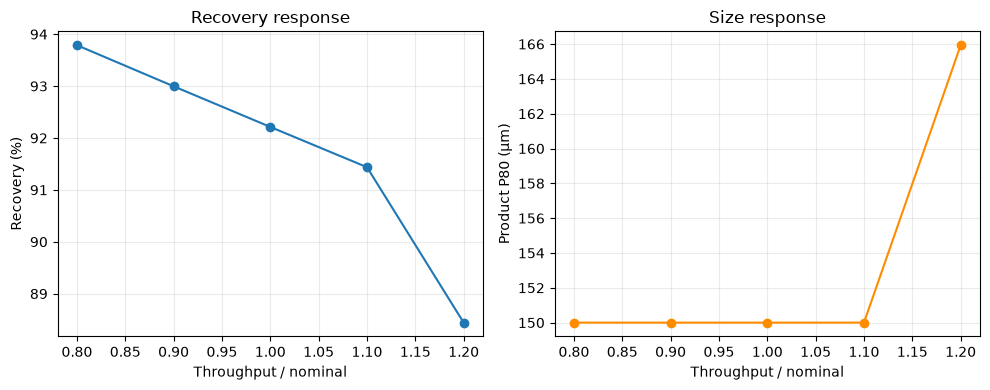

In [11]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_0_8, response_0_9, response_1_0, response_1_1, response_1_2]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


Figure 28 in the level 3 03 learning lesson reports outputs of independently solved operating points. For figure 28 in level 3 03 learning, each mark is a separate model evaluation at its stated setting. For figure 28 in level 3 03 learning, check recovery, size and energy against the contract limits. The line in figure 28 only guides comparison.

At level 3 in 03 learning, interpretation 1 is that every supervised target in this repository is generated by the OreFlow process engine. At level 3 in 03 learning, interpretation 2 is that the learner therefore approximates a deterministic simulator, not an instrumented plant. At level 3 in 03 learning, interpretation 3 is that interpolation splits measure performance among states drawn from cases represented during training. At level 3 in 03 learning, interpretation 4 is that whole-case and ore-group splits remove increasingly related examples and provide more demanding transfer questions. At level 3 in 03 learning, interpretation 5 is that the split unit must match the intended deployment because a random row split can leak a case signature through correlated process variables. At level 3 in 03 learning, interpretation 6 is that scaling, feature selection and tuning belong inside each training fold. At level 3 in 03 learning, interpretation 7 is that report errors by target and by held-out group rather than only one pooled score, since a good average can hide severe failure for an unfamiliar mineral family. At level 3 in 03 learning, interpretation 8 is that prediction intervals require empirical coverage checks. At level 3 in 03 learning, interpretation 9 is that these evaluations do not establish causal effects or validate operating decisions. At level 3 in 03 learning, interpretation 10 is that plant observations and a decision-specific loss are required for those separate questions. At level 3 in 03 learning, interpretation 11 is that the committed design contains 3,072 simulated states from twelve authored circuits. At level 3 in 03 learning, interpretation 12 is that that size improves repeatability of the experiment but does not create 3,072 independent geological settings, since rows share case definitions, mineral parameters and circuit assumptions. At level 3 in 03 learning, interpretation 13 is that a model trained against those labels can reproduce simulator behaviour very accurately and still be wrong about a real plant. At level 3 in 03 learning, interpretation 14 is that for transfer claims, inspect per-case residuals, target scaling and which ore groups are absent from training. At level 3 in 03 learning, interpretation 15 is that a grouped split prevents near-duplicate rows from crossing the boundary, but it cannot test a mineral family that the study never sampled. At level 3 in 03 learning, interpretation 16 is that compare the learned prediction with the exact process result before using it to rank candidate operating decisions. At level 3 in 03 learning, extension 1 shows that a fair model comparison uses identical folds, targets, preprocessing and tuning budgets. At level 3 in 03 learning, extension 2 shows that the selected estimator should be chosen inside training folds because using held-out cases to select a model turns the final score into another tuning result. At level 3 in 03 learning, extension 3 shows that retain a simple baseline such as a training-mean predictor and show the distribution over held-out groups, because it reveals whether added complexity helps transfer rather than only interpolation.

## Results

**Answer:** In this level 3 03 learning lesson, the executed circuit reports recovery of 93.788 percent at the first controlled throughput setting for Compare surrogates and transfer to unseen ores.

Compare the heatmap within each target. The gap between pooled and within-case R² exposes case-mean effects. Whole-case and ore-group holdouts are harder transfer tests, not guarantees for future plants. GP coverage is empirical on this generated split. Every label comes from the same process engine; independent plant data are required for field validation.

## Summary

The bounded result is that the surrogates approximate OreFlow's own engine over twelve authored circuits. The notebook reports how performance changes under stricter holdouts and does not claim general plant predictive capability or a novel learning algorithm.

## References

- https://doi.org/10.1023/A:1010933404324
- https://doi.org/10.1214/aos/1013203451
- https://doi.org/10.48550/arXiv.1412.6980
- https://doi.org/10.1017/CBO9780511790423
- https://doi.org/10.1023/A:1010933404324